In [39]:
from pynq.overlays.base import BaseOverlay
import xrfdc, numpy as np, matplotlib.pyplot as plt

base = BaseOverlay('base.bit')
base.init_rf_clks()

tx  = base.radio.transmitter.channel[0]        # DAC_B
rxs = base.radio.receiver.channel              # 4 ADC channels

print("DAC:", tx.dac_block.MixerSettings, "zone", tx.dac_block.NyquistZone)
for i, ch in enumerate(rxs):
    print(f"ADC {i}:", ch.adc_block.MixerSettings, "zone", ch.adc_block.NyquistZone)

DAC: {'Freq': 1228.8, 'PhaseOffset': 0.0, 'EventSource': 0, 'CoarseMixFreq': 0, 'MixerMode': 2, 'FineMixerScale': 1, 'MixerType': 2} zone 1
ADC 0: {'Freq': -1228.8, 'PhaseOffset': 0.0, 'EventSource': 2, 'CoarseMixFreq': 0, 'MixerMode': 3, 'FineMixerScale': 1, 'MixerType': 2} zone 1
ADC 1: {'Freq': -1228.8, 'PhaseOffset': 0.0, 'EventSource': 2, 'CoarseMixFreq': 0, 'MixerMode': 3, 'FineMixerScale': 1, 'MixerType': 2} zone 1
ADC 2: {'Freq': -1228.8, 'PhaseOffset': 0.0, 'EventSource': 2, 'CoarseMixFreq': 0, 'MixerMode': 3, 'FineMixerScale': 1, 'MixerType': 2} zone 1
ADC 3: {'Freq': -1228.8, 'PhaseOffset': 0.0, 'EventSource': 2, 'CoarseMixFreq': 0, 'MixerMode': 3, 'FineMixerScale': 1, 'MixerType': 2} zone 1


In [15]:
print("DAC interpolation:", tx.dac_block.InterpolationFactor)
for i, ch in enumerate(rxs):
    print(f"ADC {i} decimation:", ch.adc_block.DecimationFactor)

print("DAC:", tx.dac_block.BlockStatus)
print("ADC:", rxs[0].adc_block.BlockStatus)

DAC interpolation: 2
ADC 0 decimation: 2
ADC 1 decimation: 2
ADC 2 decimation: 2
ADC 3 decimation: 2
DAC: {'SamplingFreq': 4.9152, 'AnalogDataPathStatus': 16, 'DigitalDataPathStatus': 8225, 'DataPathClocksStatus': 1, 'IsFIFOFlagsEnabled': 3, 'IsFIFOFlagsAsserted': 0}
ADC: {'SamplingFreq': 4.9152, 'AnalogDataPathStatus': 1, 'DigitalDataPathStatus': 801, 'DataPathClocksStatus': 1, 'IsFIFOFlagsEnabled': 3, 'IsFIFOFlagsAsserted': 0}


In [40]:
tx  = base.radio.transmitter.channel[0]
blk = tx.dac_block

def set_tone(nco_mhz, zone, gain=0.25):
    tx.control.enable = False
    blk.NyquistZone = zone
    blk.MixerSettings['Freq'] = nco_mhz
    tx.control.gain = gain
    tx.control.enable = True
    print(f"Zone: {blk.NyquistZone} | NCO: {blk.MixerSettings['Freq']:.3f} MHz | enable: {tx.control.enable}")

def tone_off():
    tx.control.enable = False
    print("Output disabled")

### This cell is just to detect the peak at each channel. I used it to find out which labels on the board correspond to which chanels. Turns out the numbering is reverse, so base.radio.receiver.channel[0] is ACD

Zone: 2 | NCO: 784.800 MHz | enable: 1
ch 1: tone  -64.5 dBFS at   0.000 MHz | ADC offset  -71.4 dBFS at  -784.8 MHz | floor -111.8 dB


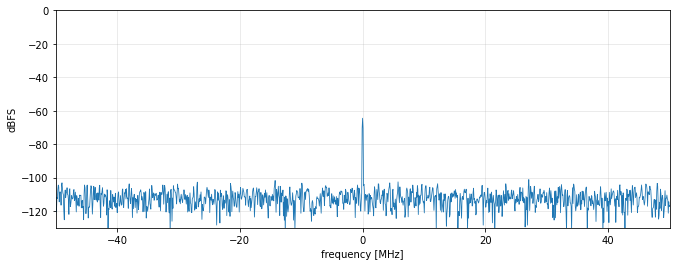

In [47]:
#set_tone(784.8, zone=2, gain=0.5)

FS_RX = 4915.2e6 / 2          # 2.4576 GS/s complex after ÷2
N = 2**15

def tone_check(i, f_expect=0.0, span=5e6):
    x = rxs[i].transfer(N)
    w = np.hanning(N)
    X = np.fft.fftshift(np.fft.fft(x * w)) / w.sum()
    f = np.fft.fftshift(np.fft.fftfreq(N, 1 / FS_RX))
    P = 20 * np.log10(np.abs(X) + 1e-15)
    near = np.abs(f - f_expect) < span                       # search only around the expected tone
    k = np.flatnonzero(near)[np.argmax(P[near])]
    dc = np.argmin(np.abs(f - rxs[i].adc_block.MixerSettings['Freq'] * 1e6))   # where the ADC offset lands
    print(f"ch {i}: tone {P[k]:6.1f} dBFS at {f[k]/1e6:7.3f} MHz | "
          f"ADC offset {P[dc]:6.1f} dBFS at {f[dc]/1e6:7.1f} MHz | floor {np.median(P):6.1f} dB")
    return f, P


#f, P = tone_check(0)          # then tone_check(1), tone_check(2), tone_check(3) in separate cells

In [46]:
tone_off()

Output disabled


### This next cell runs a quick "spectrum analyzer" on the ADC with a negative NCO frequency

Zone: 2 | NCO: 784.800 MHz | enable: 1
ADC NCO now: -784.8 MHz, zone 1
ch 1: tone  -64.5 dBFS at   0.000 MHz | ADC offset  -71.6 dBFS at  -784.8 MHz | floor -111.5 dB


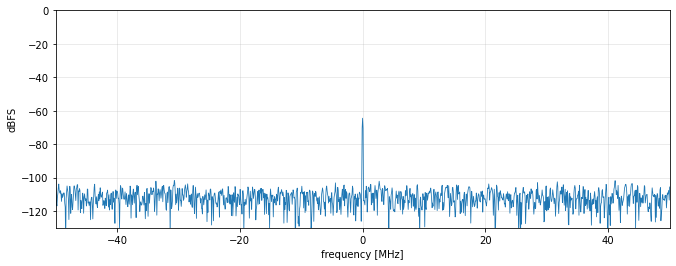

In [43]:
set_tone(784.8, zone=2, gain=0.5)

rx = rxs[1]                                      # ADC_C
rx.adc_block.NyquistZone = 1                     # 5.7 GHz is in zone 3 (odd)
rx.adc_block.MixerSettings['Freq'] = -784.8      # bring the 784.8 MHz alias to 0 Hz
rx.adc_block.UpdateEvent(xrfdc.EVENT_MIXER)
print("ADC NCO now:", rx.adc_block.MixerSettings['Freq'], "MHz, zone", rx.adc_block.NyquistZone)

N = 2**15
f, P = tone_check(1)                             # expect: peak at ~0.00 MHz

plt.figure(figsize=(11, 4))
plt.plot(f / 1e6, P, lw=0.8)
plt.xlim(-50, 50); plt.ylim(-130, 0)
plt.xlabel("frequency [MHz]"); plt.ylabel("dBFS"); plt.grid(alpha=0.3)


In [53]:
tone_off()

Output disabled


In [50]:
set_tone(785.8, zone=2, gain=0.5)          # TX 1 MHz higher
tone_check(1, f_expect=+1e6)
tone_check(1, f_expect=-1e6)
set_tone(784.8, zone=2, gain=0.5)          # back to 5.7 GHz

Zone: 2 | NCO: 785.800 MHz | enable: 1
ch 1: tone  -64.9 dBFS at   0.975 MHz | ADC offset  -71.1 dBFS at  -784.8 MHz | floor -111.5 dB
ch 1: tone  -64.9 dBFS at   0.975 MHz | ADC offset  -70.5 dBFS at  -784.8 MHz | floor -111.4 dB
Zone: 2 | NCO: 784.800 MHz | enable: 1


In [52]:
for g in (0.5, 0.25, 0.125):
    set_tone(784.8, zone=2, gain=g)
    tone_check(1)


Zone: 2 | NCO: 784.800 MHz | enable: 1
ch 1: tone  -64.5 dBFS at   0.000 MHz | ADC offset  -71.1 dBFS at  -784.8 MHz | floor -111.4 dB
Zone: 2 | NCO: 784.800 MHz | enable: 1
ch 1: tone  -70.6 dBFS at   0.000 MHz | ADC offset  -73.0 dBFS at  -784.8 MHz | floor -111.5 dB
Zone: 2 | NCO: 784.800 MHz | enable: 1
ch 1: tone  -76.4 dBFS at   0.000 MHz | ADC offset  -71.7 dBFS at  -784.8 MHz | floor -111.5 dB
